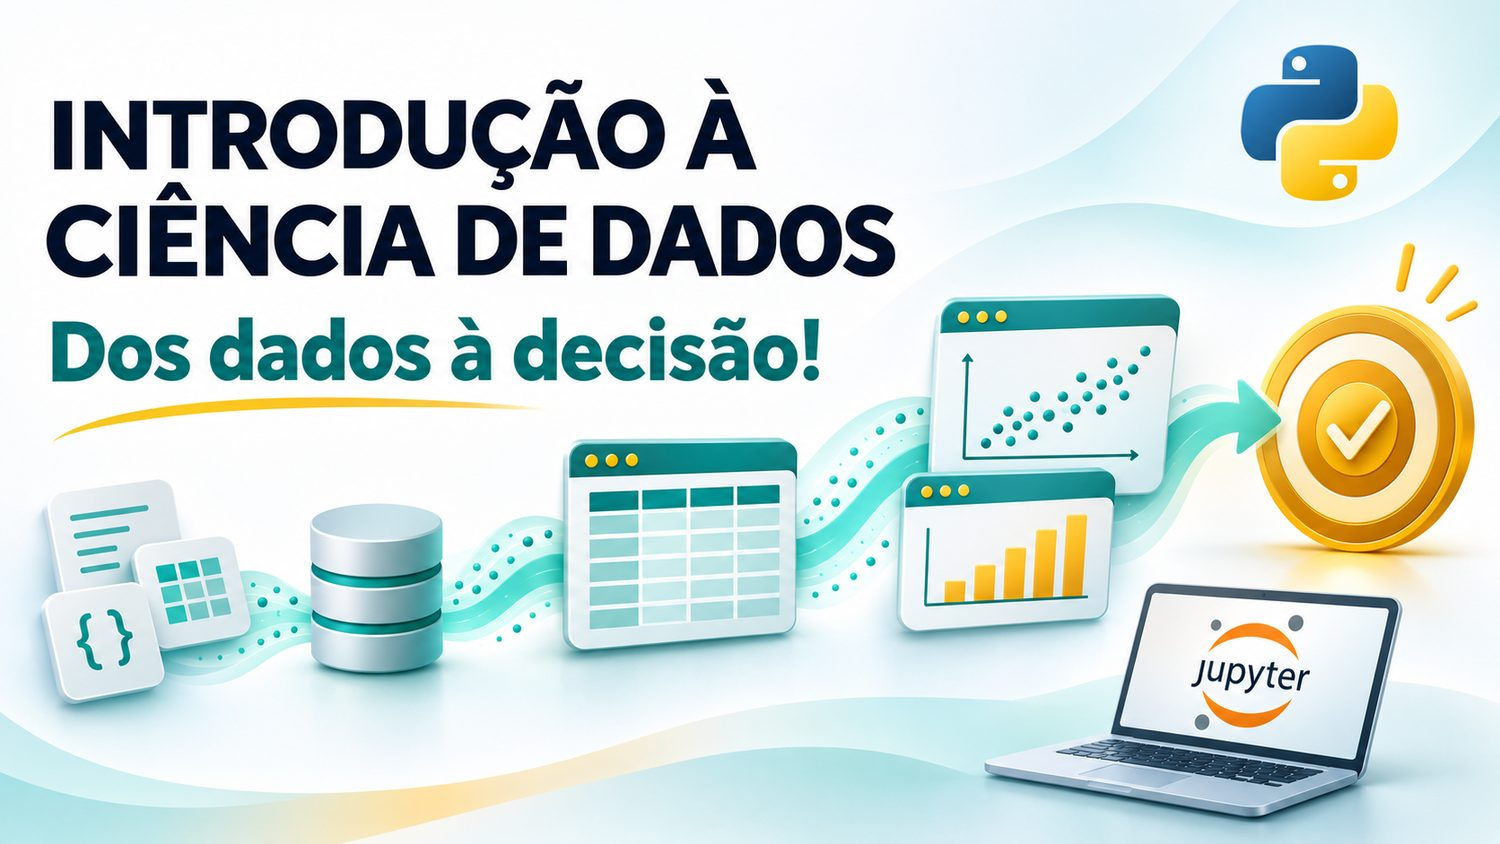

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_2_fontes_tipos_estruturas/05_Projeto_Plano_de_Dados.ipynb)

# Capítulo 5 – Projeto: desenhar um plano de dados

No módulo 1 enquadraste um problema. Neste projeto dás o passo seguinte: decidir, antes de recolher o que quer que seja, que dados vais usar, de onde vêm, como os representas e se podes confiar neles. O resultado é um **plano de dados** de uma página.

> **Objetivos:** definir o alvo, o momento da previsão e a regra do rótulo de um problema novo; escolher fontes e indicar o que verificar em cada uma; descrever as variáveis com significado, tipo, unidade e disponibilidade; identificar as chaves de ligação e os riscos de qualidade.

**Pré-requisitos:** capítulos 1 a 4 deste módulo.

**Duração sugerida:** 60 minutos, a solo ou em grupo.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Cores usadas em todo o tutorial (sempre com o mesmo significado)
AZUL, VERDE, VIOLETA, LARANJA = "#2a78d6", "#1baf7a", "#6250d6", "#eb6834"
BOM, MAU, AVISO, CINZA, TINTA = "#0ca30c", "#d03b3b", "#fab219", "#b4bdc8", "#131c26"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})


def tela(largura, altura, tamanho=(10, 3)):
    """Cria uma figura vazia, sem eixos, para desenhar esquemas."""
    fig, ax = plt.subplots(figsize=tamanho)
    ax.set_xlim(0, largura)
    ax.set_ylim(0, altura)
    ax.axis("off")
    return fig, ax


def caixa(ax, x, y, largura, altura, texto, cor, tamanho=10, negrito=False):
    """Desenha uma caixa arredondada com texto centrado."""
    ax.add_patch(FancyBboxPatch((x, y), largura, altura, boxstyle="round,pad=0.02,rounding_size=0.1",
                                fc=cor + "30", ec=cor, lw=1.6))
    ax.text(x + largura / 2, y + altura / 2, texto, ha="center", va="center", color=TINTA,
            fontsize=tamanho, linespacing=1.45, fontweight="bold" if negrito else "normal")


def seta(ax, inicio, fim, cor="#465463", **opcoes):
    """Desenha uma seta entre dois pontos."""
    opcoes.setdefault("arrowstyle", "-|>")
    ax.add_patch(FancyArrowPatch(inicio, fim, mutation_scale=14, color=cor, lw=1.5, **opcoes))

## As quatro partes de um plano de dados

| Parte | Perguntas | Capítulo |
| --- | --- | --- |
| **1. O que vamos prever** | Qual é o alvo? Em que momento se faz a previsão? Com que regra se constrói o rótulo a partir do que se observa? | 1 |
| **2. Fontes** | Que fontes servem a pergunta? Que dados dá cada uma? O que verificar antes de a usar? Que chaves as ligam? | 1 |
| **3. Variáveis** | O que significa cada variável? De que tipo é, em que unidade e como se guarda? É conhecida no momento da previsão? | 2 e 3 |
| **4. Confiança** | Que problemas de qualidade são prováveis? Quem ou o que pode ficar de fora? | 4 |

A função seguinte desenha o plano a partir de três estruturas simples: um dicionário e duas tabelas.

In [2]:
import textwrap


def desenhar_plano(titulo, previsao, fontes, variaveis, riscos):
    """Desenha um plano de dados.

    previsao  – dicionário com as chaves «alvo», «momento» e «regra do rótulo»
    fontes    – lista de tuplos (fonte, dados que fornece, o que verificar)
    variaveis – lista de tuplos (nome, significado, tipo, unidade, conhecida no momento da previsão?)
    riscos    – lista de frases
    """
    linhas = 3 + (len(fontes) + 1) + (len(variaveis) + 1) + len(riscos)
    altura_total = 1.3 + 4 * 0.75 + 0.5 * linhas + 3 * 0.25 + 0.2
    fig, ax = tela(16, altura_total, (14, altura_total * 0.44))
    y = altura_total - 0.5
    ax.text(0.1, y, titulo, fontsize=14, fontweight="bold")
    y -= 0.5

    def bloco(nome, cor, cabecalho, registos, larguras, y):
        altura = 0.75 + 0.5 * (len(registos) + (1 if cabecalho else 0))
        caixa(ax, 0.1, y - altura, 15.8, altura, "", cor)
        ax.text(0.3, y - 0.4, nome, fontweight="bold", color=cor, fontsize=11)
        yy = y - 0.88
        if cabecalho:
            x = 0.3
            for texto, largura in zip(cabecalho, larguras):
                ax.text(x, yy, texto, fontsize=8.3, fontweight="bold", color="#465463")
                x += largura
            yy -= 0.5
        for registo in registos:
            x = 0.3
            for texto, largura in zip(registo, larguras):
                ax.text(x, yy, textwrap.shorten(str(texto), int(largura * 10.5), placeholder="…"), fontsize=8.6)
                x += largura
            yy -= 0.5
        return y - altura - 0.25

    y = bloco("1. O QUE VAMOS PREVER", AZUL, None, [(chave.upper(), valor) for chave, valor in previsao.items()], [2.6, 13], y)
    y = bloco("2. FONTES", VERDE, ["Fonte", "Dados que fornece", "O que verificar"], fontes, [3.6, 5.6, 6.4], y)
    y = bloco("3. VARIÁVEIS", VIOLETA, ["Nome", "Significado", "Tipo", "Unidade", "Conhecida?"], variaveis, [3.2, 5.6, 2.6, 2.2, 2.0], y)
    bloco("4. RISCOS DE QUALIDADE", LARANJA, None, [(f"• {r}",) for r in riscos], [15.5], y)
    plt.show()

## Exemplo resolvido: as padarias

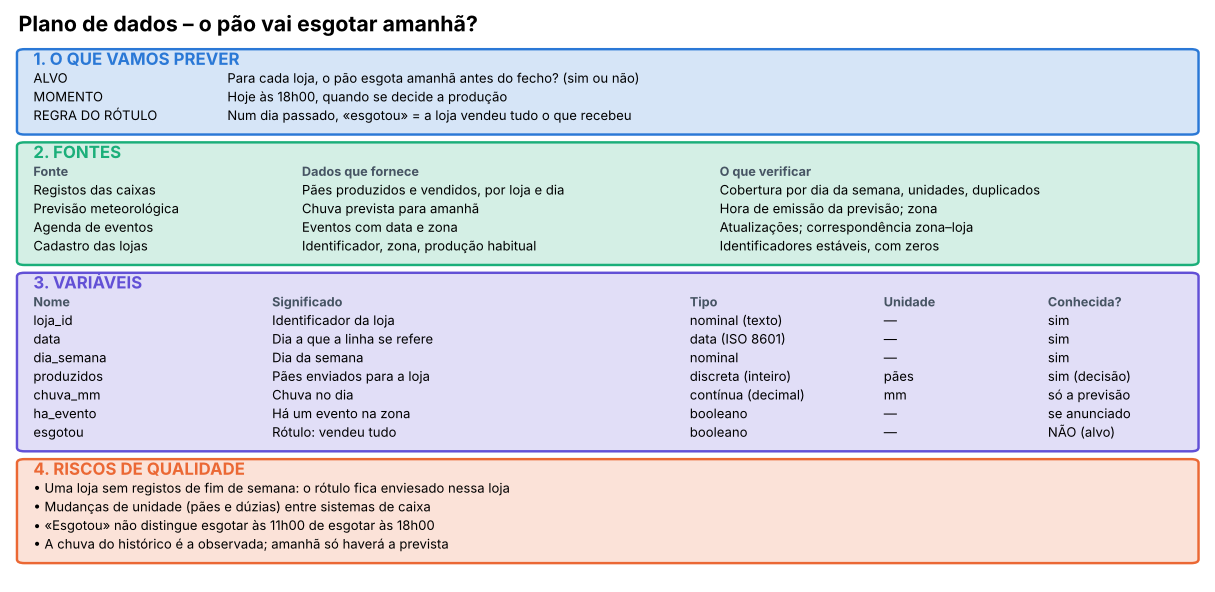

In [3]:
desenhar_plano(
    "Plano de dados – o pão vai esgotar amanhã?",
    {"alvo": "Para cada loja, o pão esgota amanhã antes do fecho? (sim ou não)",
     "momento": "Hoje às 18h00, quando se decide a produção",
     "regra do rótulo": "Num dia passado, «esgotou» = a loja vendeu tudo o que recebeu"},
    [("Registos das caixas", "Pães produzidos e vendidos, por loja e dia", "Cobertura por dia da semana, unidades, duplicados"),
     ("Previsão meteorológica", "Chuva prevista para amanhã", "Hora de emissão da previsão; zona"),
     ("Agenda de eventos", "Eventos com data e zona", "Atualizações; correspondência zona–loja"),
     ("Cadastro das lojas", "Identificador, zona, produção habitual", "Identificadores estáveis, com zeros")],
    [("loja_id", "Identificador da loja", "nominal (texto)", "—", "sim"),
     ("data", "Dia a que a linha se refere", "data (ISO 8601)", "—", "sim"),
     ("dia_semana", "Dia da semana", "nominal", "—", "sim"),
     ("produzidos", "Pães enviados para a loja", "discreta (inteiro)", "pães", "sim (decisão)"),
     ("chuva_mm", "Chuva no dia", "contínua (decimal)", "mm", "só a previsão"),
     ("ha_evento", "Há um evento na zona", "booleano", "—", "se anunciado"),
     ("esgotou", "Rótulo: vendeu tudo", "booleano", "—", "NÃO (alvo)")],
    ["Uma loja sem registos de fim de semana: o rótulo fica enviesado nessa loja",
     "Mudanças de unidade (pães e dúzias) entre sistemas de caixa",
     "«Esgotou» não distingue esgotar às 11h00 de esgotar às 18h00",
     "A chuva do histórico é a observada; amanhã só haverá a prevista"])

## Escolhe um cenário

### Cenário A – Parque de estacionamento

Um hospital tem um parque com 400 lugares que enche em certas manhãs. Quer avisar os utentes na véspera quando for de esperar que o parque esteja cheio às 10h00.

- **Para pensar:** o que quer dizer «cheio»? Que fontes existem (cancelas, marcações de consultas, calendário, meteorologia)? As cancelas contam entradas e saídas ou só entradas? O que acontece nos dias em que a cancela está avariada e fica aberta?

### Cenário B – Biblioteca municipal

Uma rede de bibliotecas quer prever que livros vão ter lista de espera no próximo mês, para decidir que exemplares comprar.

- **Para pensar:** a unidade é o título, o exemplar ou o título em cada biblioteca? O identificador é o ISBN (que começa muitas vezes por zero e muda de edição para edição)? Os pedidos de quem desistiu de esperar ficam registados? Que fontes externas ajudariam (prémios literários, programas escolares, adaptações ao cinema)?

### Cenário C – Recolha de resíduos

Um município instalou sensores de enchimento em parte dos seus contentores e quer prever quais vão estar cheios amanhã, para planear as rotas de recolha.

- **Para pensar:** que contentores têm sensor, e porquê esses? A percentagem de enchimento é medida da mesma forma em todos os modelos de sensor? Um sensor sem bateria comunica zero ou não comunica? Que outras fontes existem (queixas de munícipes, feiras e mercados, turismo)?

## Parte 1 – O que vamos prever (10 minutos)

Preenche o dicionário. A regra do rótulo deve permitir a qualquer pessoa, com os dados na mão, decidir sem hesitar se um dia passado conta como «sim» ou como «não».

In [4]:
a_minha_previsao = {
    "alvo": "...",
    "momento": "...",
    "regra do rótulo": "...",
}

## Parte 2 – Fontes e variáveis (30 minutos)

Indica pelo menos três fontes e seis variáveis. Para cada variável, pergunta: faz sentido somar dois valores desta coluna? Em que unidade está? Vou conhecê-la no momento da previsão?

In [5]:
as_minhas_fontes = [
    # (fonte, dados que fornece, o que verificar)
    ("...", "...", "..."),
]

as_minhas_variaveis = [
    # (nome, significado, tipo, unidade, conhecida no momento da previsão?)
    ("...", "...", "...", "...", "..."),
]

## Parte 3 – Confiança (10 minutos)

Indica pelo menos três riscos de qualidade **específicos do teu cenário**. Pelo menos um deve ser de enviesamento: quem ou o que pode não estar nos dados?

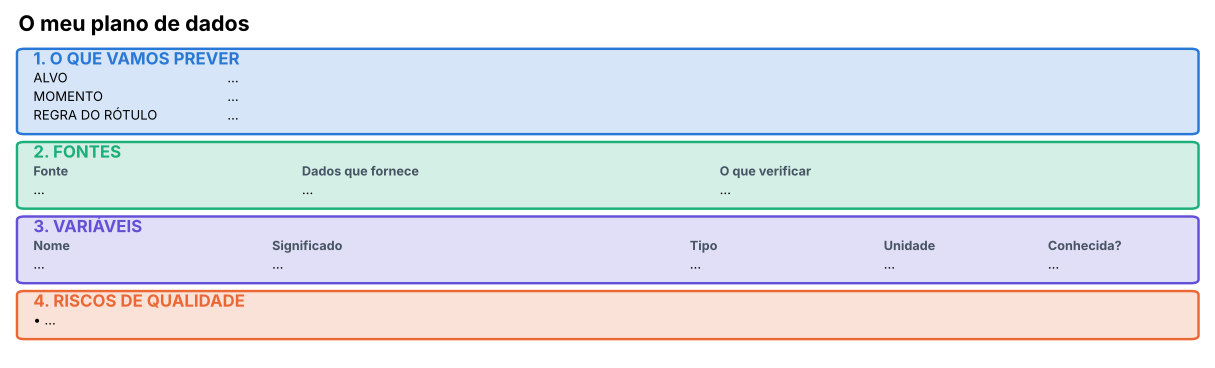

In [6]:
os_meus_riscos = [
    "...",
]

desenhar_plano("O meu plano de dados", a_minha_previsao, as_minhas_fontes, as_minhas_variaveis, os_meus_riscos)

## Parte 4 – Pôr o plano à prova (10 minutos)

Troca o plano com outro grupo, ou responde tu a estas perguntas:

1. Duas pessoas que aplicassem a tua regra do rótulo aos mesmos dados chegariam à mesma resposta?
2. Há alguma variável da tua lista que só se conhece depois do momento da previsão?
3. Com que chaves se ligam as tuas fontes? Têm o mesmo significado e o mesmo formato em todas?
4. Há algum identificador que pareça um número?
5. Que parte da realidade fica sistematicamente fora dos teus dados?
6. Qual das tuas fontes é a mais fácil de obter? É também a mais adequada?

## Grelha de autoavaliação

| Critério | Insuficiente | Bom |
| --- | --- | --- |
| Alvo e momento | «Prever a ocupação» | Diz o quê, para que unidade, para que intervalo, e quando se faz a previsão |
| Regra do rótulo | Depende de interpretação | Aplica-se aos dados sem ambiguidade |
| Fontes | Uma só fonte, ou «dados da empresa» | Várias fontes, cada uma com o que fornece e o que há a verificar |
| Variáveis | Só os nomes | Significado, tipo, unidade e disponibilidade no momento da previsão |
| Chaves | Não referidas | Identificadas, com atenção ao formato dos identificadores |
| Riscos | Genéricos | Específicos, incluindo pelo menos um de cobertura ou enviesamento |

## Soluções possíveis

<details>
<summary><b>Ver um plano possível para o cenário A (parque de estacionamento)</b></summary>

**Previsão.** Alvo: o parque está cheio amanhã entre as 10h00 e as 10h15? Momento: hoje às 17h00. Regra do rótulo: «cheio» = ocupação igual ou superior a 95% dos lugares durante todo o intervalo.

**Fontes.** Registos das cancelas (entradas e saídas com hora; verificar avarias e dias de cancela aberta). Sistema de marcações (número de consultas e exames marcados por hora; verificar se inclui as urgências). Calendário (feriados, greves de transportes anunciadas). Previsão meteorológica (chuva; hora de emissão).

**Variáveis.** `data` (data); `dia_semana` (nominal); `consultas_marcadas_9h_11h` (discreta, consultas, conhecida); `ocupacao_10h_semana_anterior` (contínua, %, conhecida); `chuva_prevista_mm` (contínua, mm, só a previsão); `greve_transportes` (booleano, se anunciada); `cheio` (booleano, alvo).

**Riscos.** Nos dias de cancela avariada e aberta não há contagens, e são provavelmente dias de muito movimento (enviesamento). A ocupação calcula-se por diferença entre entradas e saídas, e os erros acumulam-se ao longo do dia. Os carros que desistem por o parque estar cheio não ficam registados: a procura real é superior à observada.

</details>

<details>
<summary><b>Ver um plano possível para o cenário B (biblioteca municipal)</b></summary>

**Previsão.** Alvo: para cada título, haverá lista de espera no próximo mês? Momento: último dia de cada mês. Regra do rótulo: «lista de espera» = pelo menos três reservas ativas em simultâneo em qualquer dia do mês.

**Fontes.** Sistema de empréstimos (empréstimos, devoluções e reservas; verificar se as reservas canceladas ficam guardadas). Catálogo (título, autor, género, número de exemplares; verificar a ligação entre edições do mesmo título). Listas externas (prémios, leituras escolares, estreias; verificar datas e fonte).

**Variáveis.** `titulo_id` (nominal, texto: agrupa as várias edições); `isbn` (nominal, texto, com zeros à esquerda); `genero` (nominal); `exemplares` (discreta, exemplares); `reservas_mes_anterior` (discreta, reservas, conhecida); `dias_medios_de_emprestimo` (contínua, dias); `leitura_escolar` (booleano, conhecida se a lista já foi publicada); `lista_de_espera` (booleano, alvo).

**Riscos.** O ISBN lido como número perde zeros e separa edições do mesmo livro. Quem vê uma lista longa e não reserva não fica registado. Os títulos novos não têm histórico. As bibliotecas pequenas têm menos reservas por terem menos leitores, não por haver menos interesse.

</details>

<details>
<summary><b>Ver um plano possível para o cenário C (recolha de resíduos)</b></summary>

**Previsão.** Alvo: cada contentor estará cheio amanhã às 6h00, hora de saída dos camiões? Momento: hoje às 20h00. Regra do rótulo: «cheio» = enchimento igual ou superior a 85% na última leitura antes das 6h00.

**Fontes.** Sensores de enchimento (percentagem, de hora a hora; verificar modelo do sensor, calibração e falhas de comunicação). Cadastro dos contentores (identificador, localização, capacidade, tipo de resíduo). Registo das recolhas (data e hora de cada despejo). Agenda de feiras, mercados e eventos. Queixas de munícipes (texto livre, com morada).

**Variáveis.** `contentor_id` (nominal, texto); `capacidade_l` (contínua, litros); `enchimento_20h_pct` (contínua, %, conhecida); `horas_desde_recolha` (contínua, horas, conhecida); `dia_semana` (nominal); `evento_proximo` (booleano, se anunciado); `cheio` (booleano, alvo).

**Riscos.** Os sensores foram instalados nos contentores com mais queixas, por isso não representam a cidade (enviesamento). Um sensor sem bateria pode comunicar 0%, que se confunde com um contentor vazio. Modelos diferentes medem o enchimento de formas diferentes. Sacos deixados ao lado do contentor não são medidos.

</details>

## Verifica o que aprendeste

- [ ] Sei definir o alvo, o momento da previsão e uma regra do rótulo sem ambiguidade.
- [ ] Sei escolher fontes para uma pergunta e indicar o que verificar em cada uma.
- [ ] Sei descrever uma variável pelo significado, pelo tipo, pela unidade e pela disponibilidade.
- [ ] Sei identificar as chaves que ligam as fontes.
- [ ] Sei antecipar riscos de qualidade específicos, incluindo de enviesamento.

## Leitura recomendada

- https://en.wikipedia.org/wiki/Data_dictionary
- https://en.wikipedia.org/wiki/Data_quality